In [1]:
import helpy
import pandas as pd
from single_analysis import Analysis


pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', 10)

In [2]:
analysis_df = helpy.get_analysis_df(.10, 100, 2)

In [3]:
# list of models to test effectiveness of
training_range = (2007, 2020)
testing_range = (2021, 2025)

base_analysis = Analysis(analysis_df, training_range=training_range, testing_range=testing_range)

base_analysis.get_predictors()

In [4]:
base_analysis.predictors

{'Residuals': <fip_predictor.FIP_Predictor at 0x76da4b148530>,
 'No FIP': <fip_predictor.FIP_Predictor at 0x76da4b0a2d20>}

In [5]:
base_analysis.predictor_results.sort_values('R2', ascending=False)

,Feature Set,Model,MAE,RMSE,R2
0,Residuals,Elastic Net,12.131600,15.216626,0.277830
1,Residuals,Random Forest,12.401651,15.528642,0.247910
3,No FIP,Random Forest,13.046077,16.514574,0.149376
2,No FIP,Elastic Net,13.147796,16.596893,0.140875


In [6]:
base_analysis.get_lppm_scores()

In [7]:
base_analysis.results_df

,PlayerName,Season,FIP-,ERA-,pivFA,...,Residuals0_rf_score,pred_No FIP0_en,No FIP0_en_score,pred_No FIP0_rf,No FIP0_rf_score
18,Aaron Civale,2021,114.279639,90.588031,91.495320,...,6.898910,99.533173,10.730010,99.792082,10.471101
19,Aaron Civale,2023,84.753358,82.963375,91.925195,...,-2.861971,100.316979,-8.392071,98.515309,-6.590401
20,Aaron Civale,2024,118.198572,110.490439,92.110243,...,5.563274,98.592649,9.113210,96.899649,10.806209
21,Aaron Civale,2025,110.313836,118.279832,92.038485,...,3.540383,96.529862,9.787109,98.365300,7.951670
48,Aaron Nola,2021,77.268658,109.811032,93.058178,...,-3.287352,96.641244,-6.911912,97.567883,-7.838552
...,...,...,...,...,...,...,...,...,...,...,...
3632,Zack Wheeler,2021,59.142138,65.997313,97.335892,...,-5.348361,87.209288,-10.090009,85.345998,-8.226720
3633,Zack Wheeler,2022,71.175719,69.673653,96.103651,...,-3.451281,90.534277,-8.877212,88.658322,-7.001256
3634,Zack Wheeler,2023,70.699745,81.310410,95.962228,...,-3.989662,91.968553,-10.633062,88.232847,-6.897356
3635,Zack Wheeler,2024,75.354912,60.249158,95.467899,...,-2.845222,95.979070,-7.957812,95.707879,-7.686621


<Figure size 1000x600 with 0 Axes>

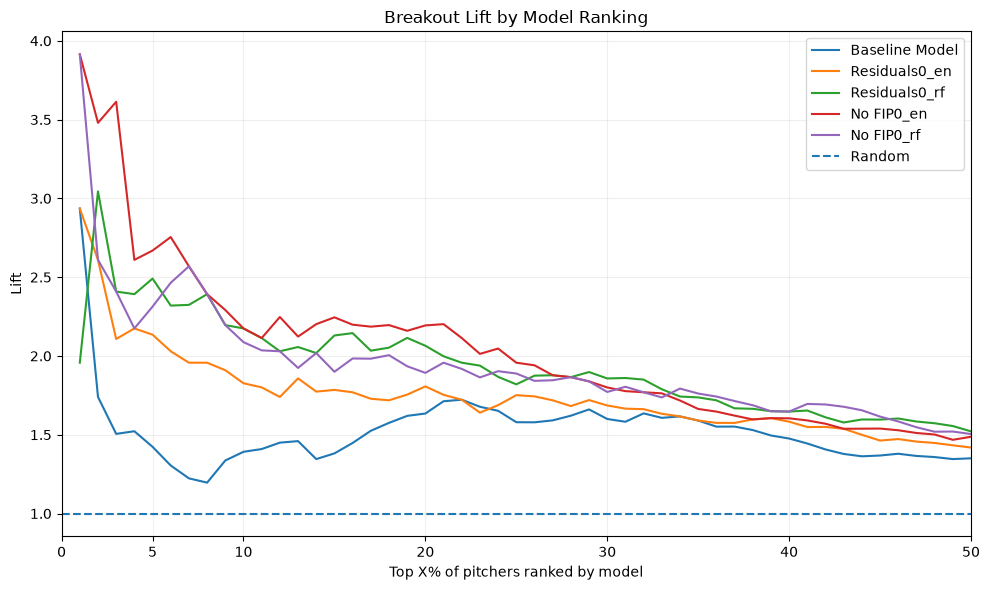

,Model,N,Breakouts,ROC-AUC,PR-AUC
0,No FIP0_en,458,117,0.729980,0.515837
1,No FIP0_rf,458,117,0.720956,0.478042
2,Residuals0_rf,458,117,0.727924,0.477337
3,Residuals0_en,458,117,0.680327,0.429423
4,Baseline Model,458,117,0.655789,0.376497


In [8]:
base_analysis.get_model_metrics(display_figure=True)

In [9]:
base_analysis.results_df[['PlayerName', 'Season', 'No FIP0_en_score', 'FIP-', 'led_to_breakout']].sort_values('No FIP0_en_score', ascending=False)

,PlayerName,Season,No FIP0_en_score,FIP-,led_to_breakout
1157,Gavin Williams,2025,19.472610,107.075247,True
2305,MacKenzie Gore,2023,19.226406,111.273603,True
3126,Shane Baz,2025,19.066808,103.954689,True
505,Carlos Rodón,2024,18.340804,104.992095,True
1269,Hunter Greene,2022,17.755135,102.804968,True
...,...,...,...,...,...
696,Clayton Kershaw,2022,-18.280509,63.841059,False
639,Chris Sale,2024,-18.366917,52.975101,False
2506,Michael King,2023,-19.221803,71.702132,False
3194,Spencer Strider,2022,-23.613879,47.624203,False


In [10]:
helpy.breakout_rate_suite(base_analysis.results_df, 'No FIP0_en_score', 'led_to_breakout')

Overall Breakout Rate: 25.55%
Top 5% Breakout Rate: 68.18%
Top 10% Breakout Rate: 55.56%
Top 25% Breakout Rate: 50.00%
Top 50% Breakout Rate: 37.99%


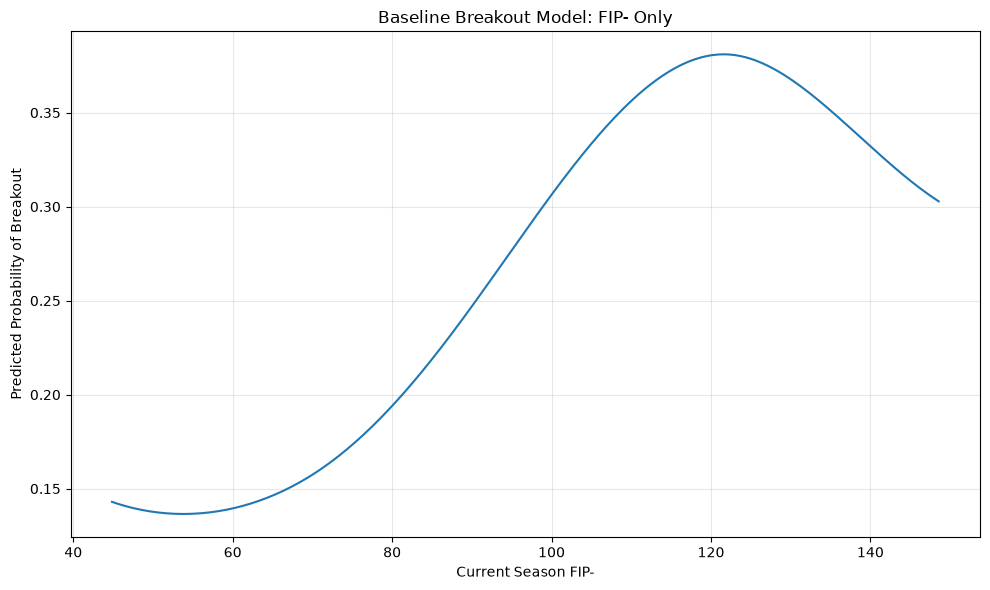

In [11]:
baseline_scores_df = helpy.create_baseline_breakout_model(analysis_df, training_range, testing_range, plot_distribution=True)

In [12]:
baseline_scores_df[['score_fip', 'FIP-', 'led_to_breakout']].sort_values('score_fip', ascending=False)

,score_fip,FIP-,led_to_breakout
1327,0.381036,121.713087,True
2149,0.381030,121.404743,True
2965,0.380987,122.103275,True
2269,0.380978,121.068526,False
970,0.380913,122.380185,False
...,...,...,...
3632,0.138733,59.142138,False
3162,0.138452,58.788482,False
2770,0.137850,57.931524,False
3261,0.137406,57.159976,False


In [13]:
helpy.breakout_rate_suite(baseline_scores_df, 'score_fip', 'led_to_breakout')

Overall Breakout Rate: 25.55%
Top 5% Breakout Rate: 36.36%
Top 10% Breakout Rate: 35.56%
Top 25% Breakout Rate: 40.35%
Top 50% Breakout Rate: 34.50%


In [14]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)